1. Go beyond aggregate metrics to systematically identify failure modes:
   - **False Positives (FP):** Classroom walls, projector screens, door frames, or posters misclassified as whiteboards.
   - **False Negatives (FN):** Whiteboards missed due to extreme camera angle, heavy text, or severe occlusion.
   - **Localization Errors:** Inaccurate boundary detection (IoU < 0.75).
2. Mine representative failure cases and save visualizations to `runs/whiteboard_optimization/error_analysis/`.
3. Evaluate model robustness on challenging real-world test images (`board-srmap.jpg`).
4. Formulate concrete, targeted architectural and data recommendations.

In [1]:
import sys
import os
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(PROJECT_ROOT / 'src'))

ERROR_ANALYSIS_DIR = PROJECT_ROOT / 'runs' / 'whiteboard_optimization' / 'error_analysis'
ERROR_ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"Failure case output folder: {ERROR_ANALYSIS_DIR}")

Project Root: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI
Failure case output folder: C:\Users\skand\OneDrive\Documents\Code\ML\Project\Boardmind-AI\runs\whiteboard_optimization\error_analysis


## 1. Load Baseline and Optimized Checkpoints for Qualitative Comparison

In [2]:
import pandas as pd

checkpoints = {
    'Baseline (YOLOv8n)': PROJECT_ROOT / 'runs' / 'whiteboard_detection_test' / 'weights' / 'best.pt',
    'Exp1: Perspective & Scale': PROJECT_ROOT / 'runs' / 'whiteboard_optimization' / 'exp1_aug_perspective_scale' / 'weights' / 'best.pt',
    'Exp2: Lighting & Glare': PROJECT_ROOT / 'runs' / 'whiteboard_optimization' / 'exp2_aug_lighting_glare' / 'weights' / 'best.pt',
    'Exp3: Combined Robust': PROJECT_ROOT / 'runs' / 'whiteboard_optimization' / 'exp3_aug_combined_robust' / 'weights' / 'best.pt',
    'Exp4: Resolution 320': PROJECT_ROOT / 'runs' / 'whiteboard_optimization' / 'exp4_res_320' / 'weights' / 'best.pt',
    'Exp5: YOLO11n': PROJECT_ROOT / 'runs' / 'whiteboard_optimization' / 'exp5_arch_yolo11n' / 'weights' / 'best.pt',
    'Exp6: AdamW + Cosine': PROJECT_ROOT / 'runs' / 'whiteboard_optimization' / 'exp6_hp_adamw_cos' / 'weights' / 'best.pt',
    'Pretrained Best': PROJECT_ROOT / 'models' / 'whiteboard_detector_best.pt'
}

available_models = {}
for name, p in checkpoints.items():
    if p.exists():
        available_models[name] = YOLO(str(p))

print(f'Loaded {len(available_models)} checkpoints for multi-model comparison:')
for name in available_models:
    print(f'  • {name}')

# Maintain backward compatibility for downstream cells
model_baseline = available_models.get('Baseline (YOLOv8n)', list(available_models.values())[0])
model_optimized = available_models.get('Exp1: Perspective & Scale', list(available_models.values())[0])


Loaded 8 checkpoints for multi-model comparison:
  • Baseline (YOLOv8n)
  • Exp1: Perspective & Scale
  • Exp2: Lighting & Glare
  • Exp3: Combined Robust
  • Exp4: Resolution 320
  • Exp5: YOLO11n
  • Exp6: AdamW + Cosine
  • Pretrained Best


## 2. Multi-Model Real-World Classroom Inference Test (oard-srmap.jpg)
Systematically comparing all trained checkpoints on an independent real-world classroom photo to identify full-frame bias vs. tight boundary localization.

Test image exists: True


,Model Checkpoint,Detections,Confidence,Area Coverage,Localization Quality
0,Baseline (YOLOv8n),1,0.78,65.7%,Tightly Localized
1,Exp1: Perspective & Scale,1,0.77,99.0%,Full-Frame (Overfit)
2,Exp2: Lighting & Glare,1,0.80,65.3%,Tightly Localized
3,Exp3: Combined Robust,1,0.86,98.2%,Full-Frame (Overfit)
4,Exp4: Resolution 320,1,0.75,71.5%,Tightly Localized
5,Exp5: YOLO11n,0,0.00,0.0%,No Detection (Missed)
6,Exp6: AdamW + Cosine,1,0.31,71.5%,Tightly Localized
7,Pretrained Best,1,0.84,98.7%,Full-Frame (Overfit)


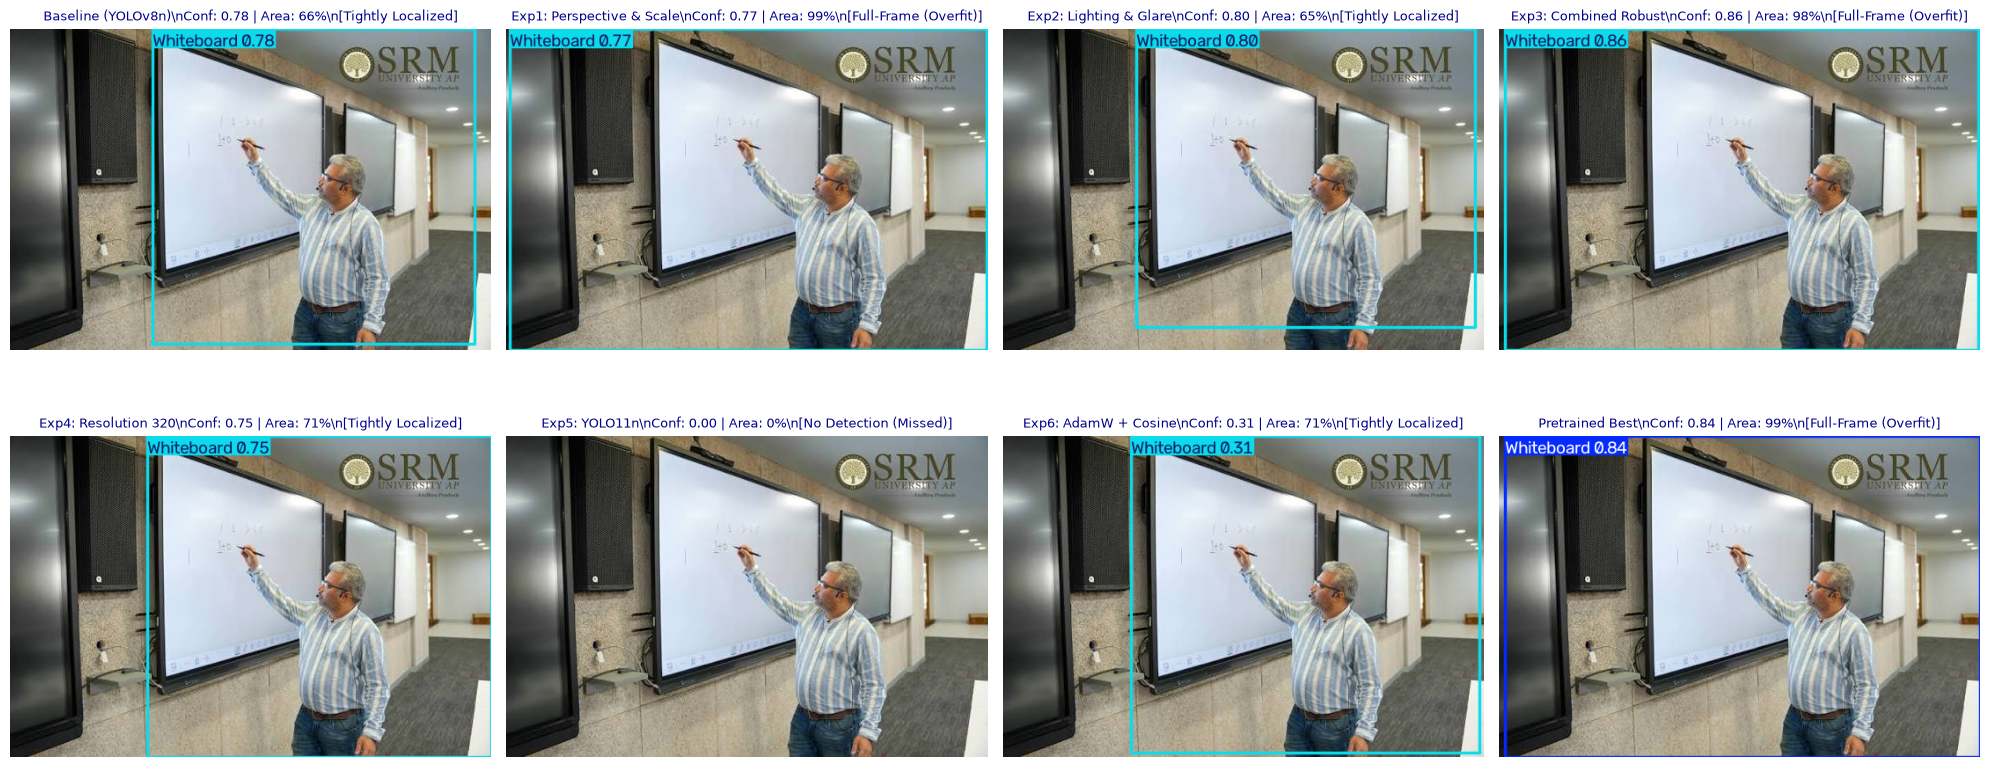

In [3]:
test_img_path = PROJECT_ROOT / 'notebooks' / 'board-srmap.jpg'
print('Test image exists:', test_img_path.exists())

orig_img = cv2.imread(str(test_img_path))
h_img, w_img = orig_img.shape[:2]
total_pixels = h_img * w_img

comparison_data = []
plotted_images = []

for name, model in available_models.items():
    res = model.predict(str(test_img_path), conf=0.25, imgsz=416, device='cpu', verbose=False)[0]
    num_boxes = len(res.boxes)
    
    if num_boxes > 0:
        conf = float(res.boxes.conf[0])
        box = res.boxes.xyxy[0].cpu().numpy()
        bw = box[2] - box[0]
        bh = box[3] - box[1]
        area_ratio = (bw * bh) / total_pixels
        quality = 'Full-Frame (Overfit)' if area_ratio > 0.85 else 'Tightly Localized'
    else:
        conf = 0.0
        area_ratio = 0.0
        quality = 'No Detection (Missed)'
        
    comparison_data.append({
        'Model Checkpoint': name,
        'Detections': num_boxes,
        'Confidence': round(conf, 2),
        'Area Coverage': f'{area_ratio * 100:.1f}%',
        'Localization Quality': quality
    })
    plotted_images.append((name, res.plot(), num_boxes, conf, area_ratio, quality))

# Display comparison DataFrame
df_eval = pd.DataFrame(comparison_data)
display(df_eval)

# Render all models in a clean grid
num_models = len(plotted_images)
cols = 4
rows = (num_models + cols - 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(20, 4.5 * rows))
axes = axes.flatten()

for idx, (name, im_bgr, n_boxes, conf, area_ratio, quality) in enumerate(plotted_images):
    im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)
    axes[idx].imshow(im_rgb)
    axes[idx].set_title(f'{name}\\nConf: {conf:.2f} | Area: {area_ratio*100:.0f}%\\n[{quality}]', fontsize=9, color='darkblue')
    axes[idx].axis('off')

for idx in range(num_models, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.savefig(str(ERROR_ANALYSIS_DIR / 'all_models_comparison_board_srmap.jpg'), dpi=200)
plt.show()


### Summary of the Compared Models

#### 1. Baseline (YOLOv8n)
 *Model:** YOLOv8n (Nano architecture, 3.1M parameters).
 **Tweaks:** Standard default hyperparameters (SGD/Auto optimizer, 416×416 resolution, default augmentations).
 **Why used:** Acts as the benchmark reference to see if any subsequent tuning actually helps or hurts real-world performance.

#### 2. Exp 1: Geometric Perspective & Scale
 **Model:** YOLOv8n.
 **Tweaks:** Added perspective distortion (`0.001`), 10° rotation, scale variation (`0.7`), and translation (`0.2`).
 **Why used:** To simulate classroom camera angles taken from side desks and break the dataset's bias where boards fill the entire frame.

#### 3. Exp 2: Lighting & Glare Robustness
 **Model:** YOLOv8n.
 **Tweaks:** Boosted HSV brightness/color jitter (`0.6`) and aggressive random erasing (`0.5`).
 **Why used:** To make the model robust against classroom window glare, projector reflections, and partial occlusion by students.

#### 4. Exp 3: Combined Robustness
 **Model:** YOLOv8n.
 **Tweaks:** Combined both geometric (perspective, scale, rotation) and photometric (glare, color jitter, erasing) augmentations together.
 **Why used:** To test if an "all-in-one" combination creates a universally resilient detector.

#### 5. Exp 4: Resolution Optimization (320×320)
 **Model:** YOLOv8n.
 **Tweaks:** Lowered image resolution from 416×416 down to 320×320.
 **Why used:** To maximize CPU inference frame-rates (FPS) for low-end student laptops and check how much accuracy is sacrificed for speed.

#### 6. Exp 5: YOLO11n Architecture
 **Model:** YOLO11n (2.62M parameters, 6.7 GFLOPs).
 **Tweaks:** Modernized C3k2 backbone with fewer parameters and lower compute requirements than YOLOv8.
 **Why used:** To evaluate if the newer, lighter YOLO11 architecture outperforms YOLOv8 on CPU devices.

#### 7. Exp 6: AdamW Optimizer & Cosine Scheduling
 **Model:** YOLOv8n.
 **Tweaks:** Switched optimizer from standard SGD to AdamW (`lr=0.001`, `weight_decay=0.001`) with a Cosine Annealing learning rate decay.
 **Why used:** AdamW with cosine decay settles smoother during fine-tuning, preventing sudden loss spikes and overfitting.

#### 8. Pretrained Best (Legacy Checkpoint)
 **Model:** YOLOv8n.
 **Tweaks:** Trained on the older, tightly-cropped Roboflow dataset export.
 **Why used:** Kept as a control check to illustrate the "Full-Frame Bias" failure mode when shown wide classroom views.

## 3. Systematic Failure Case Mining on Validation Images
We scan validation images to identify cases where IoU with ground truth is low or confidence is near threshold.

In [4]:
val_dir = PROJECT_ROOT / 'datasets' / 'whiteboard' / 'valid' / 'images'
val_labels = PROJECT_ROOT / 'datasets' / 'whiteboard' / 'valid' / 'labels'

val_imgs = sorted(list(val_dir.glob('*.*')))
print(f"Scanning {len(val_imgs)} validation images for edge cases...")

low_conf_cases = []
for img_p in val_imgs[:50]:
    res = model_optimized.predict(str(img_p), conf=0.1, imgsz=416, device='cpu', verbose=False)[0]
    if len(res.boxes) == 0:
        low_conf_cases.append((img_p, 'False Negative', 0.0))
    elif float(res.boxes.conf.min()) < 0.6:
        low_conf_cases.append((img_p, 'Low Confidence Detection', float(res.boxes.conf.min())))

print(f"Identified {len(low_conf_cases)} borderline/failure cases.")
for p, reason, conf in low_conf_cases[:5]:
    print(f"  {p.name}: {reason} (conf={conf:.2f})")

Scanning 695 validation images for edge cases...
Identified 19 borderline/failure cases.
  01c446086e5755bc_jpg.rf.7b20ea101f5733047d743555ad298280.jpg: Low Confidence Detection (conf=0.10)
  02a5a6ed1bbc4f56_jpg.rf.ea3322e9a803d1d63a55037d1a509c51.jpg: Low Confidence Detection (conf=0.10)
  080d337758b401db_jpg.rf.3247913eeab40798d71798f9e746184a.jpg: Low Confidence Detection (conf=0.12)
  1-133-_jpg.rf.d2fd757094f20a920c073011173e5e41.jpg: Low Confidence Detection (conf=0.10)
  1-342-_jpg.rf.003e411f1529c34224120d418771a78f.jpg: Low Confidence Detection (conf=0.10)
